In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# import datasets 

df_country = pd.read_csv('/Users/alivakof/Desktop/Time Series/Project/data/france_electricity_hourly.csv')

df_regional= pd.read_csv('/Users/alivakof/Desktop/Time Series/Project/data/france_regional_electricity_hourly.csv')

df_country.head()


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+0000,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+0000,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+0000,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+0000,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+0000,52972.0,52188.0,5.72


In [6]:
df_regional.head()

,region,datetime_utc,load_mw,temperature_c
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+0000,6028.0,13.3
1,Auvergne-Rhône-Alpes,2023-01-01 01:00:00+0000,6165.0,13.2
2,Auvergne-Rhône-Alpes,2023-01-01 02:00:00+0000,6282.0,13.0
3,Auvergne-Rhône-Alpes,2023-01-01 03:00:00+0000,5779.0,12.8
4,Auvergne-Rhône-Alpes,2023-01-01 04:00:00+0000,5526.0,12.7


In [ ]:
# audit regions all geographically in mainland France
unique_regions = df_regional['region'].unique().tolist()
print(f"Unique regions: {unique_regions}")

Unique regions: ['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Grand Est', 'Hauts-de-France', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']


In [20]:
# time from UTC to CET

df_country['datetime_utc'] = pd.to_datetime(df_country['datetime_utc'], utc=True)
df_country['datetime_cet'] = df_country['datetime_utc'].dt.tz_convert('Europe/Paris')

df_regional['datetime_utc'] = pd.to_datetime(df_regional['datetime_utc'], utc=True)
df_regional['datetime_cet'] = df_regional['datetime_utc'].dt.tz_convert('Europe/Paris')

df_regional.head()


,region,datetime_utc,load_mw,temperature_c,datetime_cet
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+00:00,6028.0,13.3,2023-01-01 01:00:00+01:00
1,Auvergne-Rhône-Alpes,2023-01-01 01:00:00+00:00,6165.0,13.2,2023-01-01 02:00:00+01:00
2,Auvergne-Rhône-Alpes,2023-01-01 02:00:00+00:00,6282.0,13.0,2023-01-01 03:00:00+01:00
3,Auvergne-Rhône-Alpes,2023-01-01 03:00:00+00:00,5779.0,12.8,2023-01-01 04:00:00+01:00
4,Auvergne-Rhône-Alpes,2023-01-01 04:00:00+00:00,5526.0,12.7,2023-01-01 05:00:00+01:00


In [44]:
# check difference between two datasets

regional_sum = df_regional.groupby('datetime_cet')['load_mw'].sum().reset_index()

df_check = pd.merge(df_country, regional_sum, on='datetime_cet', how='left', suffixes=('_country', '_regional_sum'))
df_check_time_equal = df_check[df_check['datetime_cet']>= '2023-01-01 01:00:00+01:00']
df_check_time_equal['residuals'] = df_check_time_equal['load_mw_country'] - df_check_time_equal['load_mw_regional_sum']

df_check_time_equal_fkd=df_check_time_equal[df_check_time_equal['residuals']!=0]

df_check_time_equal_fkd.info()


<class 'pandas.DataFrame'>
Index: 22415 entries, 35064 to 65709
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype                       
---  ------                --------------  -----                       
 0   datetime_utc          22415 non-null  datetime64[us, UTC]         
 1   load_mw_country       22412 non-null  float64                     
 2   rte_forecast_d1_mw    22412 non-null  float64                     
 3   temperature_c         22415 non-null  float64                     
 4   datetime_cet          22415 non-null  datetime64[us, Europe/Paris]
 5   load_mw_regional_sum  22415 non-null  float64                     
 6   residuals             22412 non-null  float64                     
dtypes: datetime64[us, Europe/Paris](1), datetime64[us, UTC](1), float64(5)
memory usage: 1.4 MB


In [45]:
load_columns = [
    "load_mw_country",
    "load_mw_regional_sum",
]

assert not df_regional.duplicated(
    ["datetime_utc", "region"]
).any()

n_regions = df_regional["region"].nunique()

# Require a nonmissing load for every region.
regional_load = (
    df_regional.groupby("datetime_utc")["load_mw"]
    .sum(min_count=n_regions)
    .rename("load_mw_regional_sum")
    .reset_index()
)

load_check = (
    df_country[
        ["datetime_utc", "load_mw", "rte_forecast_d1_mw"]
    ]
    .rename(columns={"load_mw": "load_mw_country"})
    .merge(
        regional_load,
        on="datetime_utc",
        how="inner",
        validate="one_to_one",
    )
)

load_check["country_minus_regions_mw"] = (
    load_check["load_mw_country"]
    - load_check["load_mw_regional_sum"]
)

# Display the largest discrepancies.
load_check.loc[
    load_check["country_minus_regions_mw"]
    .abs()
    .sort_values(ascending=False)
    .index
].head(10)

,datetime_utc,load_mw_country,rte_forecast_d1_mw,load_mw_regional_sum,country_minus_regions_mw
25139,2025-11-13 11:00:00+00:00,55340.0,52950.0,56960.0,-1620.0
30494,2026-06-24 14:00:00+00:00,58151.0,56188.0,58145.0,6.0
12634,2024-06-10 10:00:00+00:00,49396.0,49175.0,49390.0,6.0
8533,2023-12-22 13:00:00+00:00,59194.0,58250.0,59199.0,-5.0
7454,2023-11-07 14:00:00+00:00,55107.0,53988.0,55102.0,5.0
17218,2024-12-18 10:00:00+00:00,66974.0,66212.0,66979.0,-5.0
7962,2023-11-28 18:00:00+00:00,71618.0,70362.0,71613.0,5.0
8610,2023-12-25 18:00:00+00:00,51780.0,48475.0,51785.0,-5.0
9096,2024-01-15 00:00:00+00:00,65964.0,67338.0,65959.0,5.0
18218,2025-01-29 02:00:00+00:00,55064.0,53225.0,55059.0,5.0


In [46]:
def forecast_metrics(frame):
    paired = frame[
        load_columns + ["rte_forecast_d1_mw"]
    ].dropna()

    # Positive error means observed load exceeds the forecast.
    errors = paired[load_columns].sub(
        paired["rte_forecast_d1_mw"],
        axis=0,
    )

    return pd.DataFrame({
        "observations": errors.count(),
        "mean_difference": errors.mean(),
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt(errors.pow(2).mean()),
    })


hourly_metrics = forecast_metrics(load_check)
hourly_metrics

,observations,mean_difference,MAE,RMSE
load_mw_country,30643,1102.884933,1411.745488,1748.018358
load_mw_regional_sum,30643,1102.929674,1411.789511,1748.112209


In [47]:
flagged_hour = pd.Timestamp("2025-11-13 11:00:00", tz="UTC")

without_flagged_hour = load_check.loc[
    load_check["datetime_utc"].ne(flagged_hour)
]

forecast_metrics(without_flagged_hour)

,observations,mean_difference,MAE,RMSE
load_mw_country,30642,1102.842928,1411.713563,1747.993560
load_mw_regional_sum,30642,1102.834802,1411.704719,1747.990632


In [48]:
local = (
    load_check
    .set_index("datetime_utc")[
        load_columns + ["rte_forecast_d1_mw"]
    ]
    .tz_convert("Europe/Paris")
)

daily = local.resample("D").sum(min_count=1)
counts = local.resample("D").count()

# Calendar-day boundaries account for daylight saving changes.
boundaries = pd.date_range(
    start=daily.index.min(),
    periods=len(daily) + 1,
    freq="D",
)

expected_hours = pd.Series(
    (boundaries[1:] - boundaries[:-1])
    / pd.Timedelta(hours=1),
    index=daily.index,
)

# Every series must contain every expected hour.
complete_days = counts.eq(expected_hours, axis=0).all(axis=1)
daily = daily.loc[complete_days].copy()

daily["country_minus_regions_mwh"] = (
    daily["load_mw_country"]
    - daily["load_mw_regional_sum"]
)

forecast_metrics(daily)

,observations,mean_difference,MAE,RMSE
load_mw_country,1273,26449.808327,28473.651218,33926.096264
load_mw_regional_sum,1273,26450.881383,28474.732129,33927.448472


In [49]:
target = pd.Timestamp("2025-11-13 11:00:00", tz="UTC")

regional_window = (
    df_regional.loc[
        df_regional["datetime_utc"].between(
            target - pd.Timedelta(hours=2),
            target + pd.Timedelta(hours=2),
        )
    ]
    .pivot(
        index="datetime_utc",
        columns="region",
        values="load_mw",
    )
)

regional_window[
    ["Auvergne-Rhône-Alpes", "Occitanie"]
]


region,Auvergne-Rhône-Alpes,Occitanie
datetime_utc,,
2025-11-13 09:00:00+00:00,7680.0,4102.0
2025-11-13 10:00:00+00:00,7701.0,4142.0
2025-11-13 11:00:00+00:00,3826.0,9805.0
2025-11-13 12:00:00+00:00,7568.0,4410.0
2025-11-13 13:00:00+00:00,7314.0,4122.0


In [50]:
# Work on a separate copy.
r = df_regional[
    ["datetime_utc", "region", "temperature_c", "load_mw"]
].copy()

# Each region must appear at most once per timestamp.
assert not r.duplicated(["datetime_utc", "region"]).any()

expected_regions = r["region"].nunique()

# Numerator contribution for a load-weighted temperature.
r["temperature_x_load"] = r["temperature_c"] * r["load_mw"]

# Produce one row per timestamp.
hourly = r.groupby("datetime_utc").agg(
    temperature_regional_mean_c=("temperature_c", "mean"),
    weighted_numerator=("temperature_x_load", "sum"),
    total_regional_load_mw=("load_mw", "sum"),
    n_temperatures=("temperature_c", "count"),
    n_loads=("load_mw", "count"),
).reset_index()

# Pandas normally skips missing values.
# Require all regions instead of silently averaging fewer regions.
complete_temperatures = hourly["n_temperatures"].eq(expected_regions)

hourly["temperature_regional_mean_c"] = (
    hourly["temperature_regional_mean_c"]
    .where(complete_temperatures)
)

valid_weights = (
    complete_temperatures
    & hourly["n_loads"].eq(expected_regions)
    & hourly["total_regional_load_mw"].gt(0)
)

hourly["temperature_regional_load_weighted_c"] = (
    hourly["weighted_numerator"]
    / hourly["total_regional_load_mw"]
).where(valid_weights)

# Keep your existing DataFrame unchanged.
comparison = (
    df_check_time_equal[["datetime_utc", "temperature_c"]]
    .rename(columns={"temperature_c": "temperature_country_c"})
    .merge(
        hourly,
        on="datetime_utc",
        how="inner",
        validate="one_to_one",
    )
)

comparison.head()

,datetime_utc,temperature_country_c,temperature_regional_mean_c,weighted_numerator,total_regional_load_mw,n_temperatures,n_loads,temperature_regional_load_weighted_c
0,2023-01-01 00:00:00+00:00,14.20,13.416667,611200.1,45034.0,12,12,13.571970
1,2023-01-01 01:00:00+00:00,14.45,13.516667,613431.2,44922.0,12,12,13.655474
2,2023-01-01 02:00:00+00:00,14.29,13.325000,568041.2,42144.0,12,12,13.478578
3,2023-01-01 03:00:00+00:00,13.86,13.000000,519729.7,39567.0,12,12,13.135434
4,2023-01-01 04:00:00+00:00,13.63,12.683333,491404.5,38239.0,12,12,12.850872


In [51]:
candidates = [
    "temperature_regional_mean_c",
    "temperature_regional_load_weighted_c",
]

# Use identical observations when comparing the two methods.
paired = comparison[
    ["temperature_country_c", *candidates]
].dropna()

# rsub calculates country temperature minus each candidate.
errors = paired[candidates].rsub(
    paired["temperature_country_c"],
    axis=0,
)

metrics = pd.DataFrame({
    "hours": errors.count(),
    "mean_difference_c": errors.mean(),
    "mae_c": errors.abs().mean(),
    "rmse_c": np.sqrt(errors.pow(2).mean()),
    "max_absolute_difference_c": errors.abs().max(),
})

metrics

,hours,mean_difference_c,mae_c,rmse_c,max_absolute_difference_c
temperature_regional_mean_c,30643,0.111797,0.442215,0.580388,3.548333
temperature_regional_load_weighted_c,30643,0.057213,0.420980,0.549657,3.642145


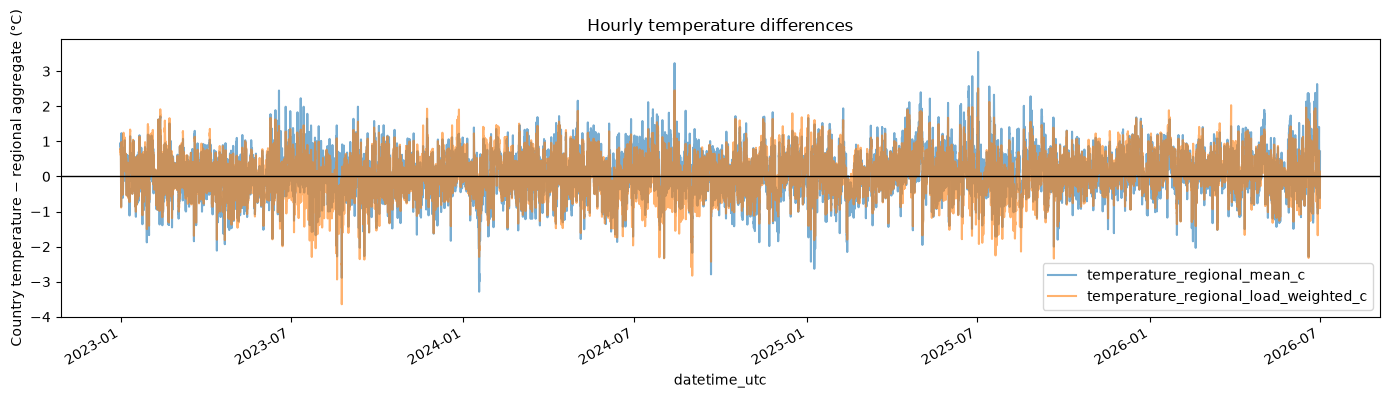

In [53]:
plot_errors = errors.copy()
plot_errors.index = pd.DatetimeIndex(
    comparison.loc[paired.index, "datetime_utc"]
)

ax = plot_errors.plot(
    figsize=(14, 4),
    alpha=0.6,
    ylabel="Country temperature − regional aggregate (°C)",
    title="Hourly temperature differences",
)

ax.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()